In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## MA(2) simulation
$y_t = u_t + \theta_1 u_{t-1} + \theta_2 u_{t-2}, \quad u_t \overset{iid}{\sim} N(0,1)$

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


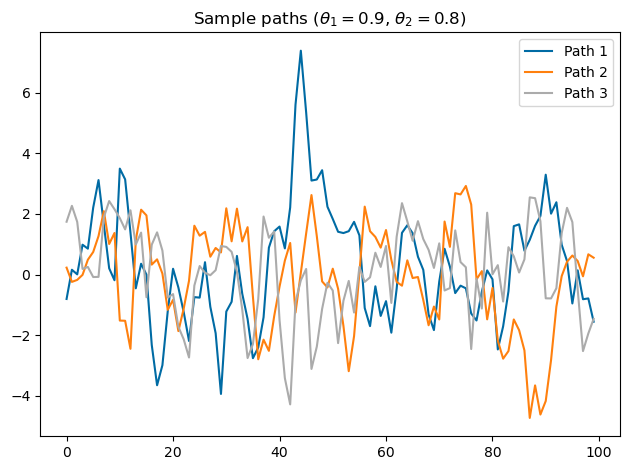

In [2]:
# Parameters
theta1 = 0.9
theta2 = 0.8
T = 100
n_paths = 3

# Simulate
rng = np.random.default_rng(seed=31150)
u = rng.standard_normal((T + 2, n_paths))
y = u[2:] + theta1 * u[1:-1] + theta2 * u[:-2]

# Plot
fig, ax = plt.subplots()
for j in range(n_paths):
    ax.plot(y[:, j], label=f'Path {j + 1}')
ax.set_title(f'Sample paths ($\\theta_1 = {theta1}$, $\\theta_2 = {theta2}$)')
ax.legend()
plt.tight_layout()
fig.savefig('output/ma_sim.eps')
plt.show()

## MA(10) simulation
$y_t = u_t + \sum_{\ell=1}^{q} \theta_\ell u_{t-\ell}, \quad \theta_\ell = 1 - \frac{\ell}{q+1}, \quad q = 10$

<>:15: SyntaxWarning: invalid escape sequence '\e'
<>:15: SyntaxWarning: invalid escape sequence '\e'
C:\Users\mikkelpm\AppData\Local\Temp\ipykernel_44256\2593801593.py:15: SyntaxWarning: invalid escape sequence '\e'
  ax.set_title(f'Sample paths (MA({q}), $\\theta_\ell = 1 - \\ell/{q + 1}$)')
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


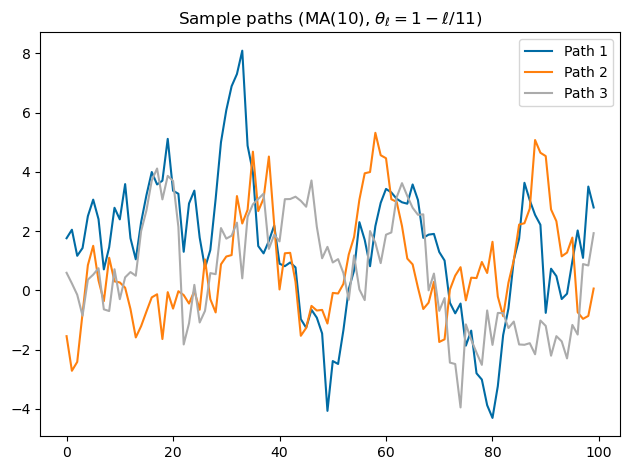

In [3]:
# Parameters
q = 10
theta = 1 - np.arange(1, q + 1) / (q + 1)

# Simulate
u = rng.standard_normal((T + q, n_paths))
y = u[q:].copy()
for j in range(q):
    y += theta[j] * u[q - 1 - j:T + q - 1 - j]

# Plot
fig, ax = plt.subplots()
for j in range(n_paths):
    ax.plot(y[:, j], label=f'Path {j + 1}')
ax.set_title(f'Sample paths (MA({q}), $\\theta_\ell = 1 - \\ell/{q + 1}$)')
ax.legend()
plt.tight_layout()
fig.savefig('output/ma10_sim.eps')
plt.show()

## ARMA(1,1) simulation
$y_t = \rho y_{t-1} + u_t + \theta u_{t-1}, \quad u_t \overset{iid}{\sim} N(0,1)$

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


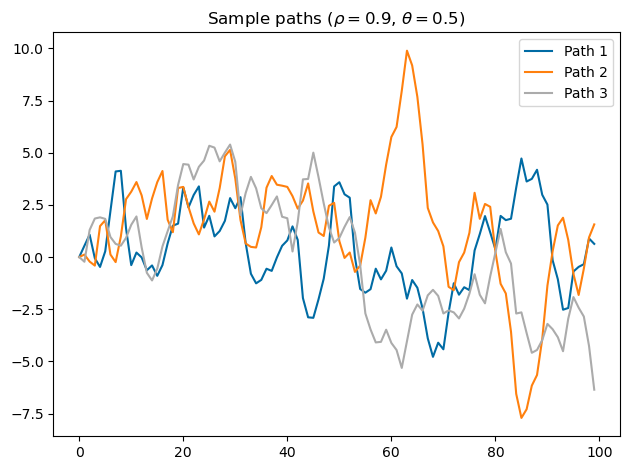

In [4]:
# Parameters
rho = 0.9
theta = 0.5

# Simulate
u = rng.standard_normal((T + 1, n_paths))
y = np.zeros((T, n_paths))
for t in range(1, T):
    y[t] = rho * y[t - 1] + u[t + 1] + theta * u[t]

# Plot
fig, ax = plt.subplots()
for j in range(n_paths):
    ax.plot(y[:, j], label=f'Path {j + 1}')
ax.set_title(f'Sample paths ($\\rho = {rho}$, $\\theta = {theta}$)')
ax.legend()
plt.tight_layout()
fig.savefig('output/arma_sim.eps')
plt.show()